In [1]:
import matplotlib.pyplot as plt
import networkx as nx
from sknetwork.hierarchy import Paris, LouvainHierarchy
import numpy as np
import seaborn as sns
from scipy.sparse import csr_matrix
import random
from IPython.display import SVG, display
from sknetwork.hierarchy import Paris, cut_straight, dasgupta_score, tree_sampling_divergence
from sknetwork.visualization import svg_graph, svg_bigraph, svg_dendrogram
import pandas as pd
from netgraph import Graph
from community_layout.layout_class import CommunityLayout
import matplotlib
from mycolorpy import colorlist as mcp
matplotlib.rcParams['figure.dpi'] = 150
random.seed(42)
np.random.seed(42)

COMMUNITY LAYOUT: Datashader not found, edge bundling not available


In [2]:
g1 = nx.gnm_random_graph(40, 400, seed=42)
g2 = nx.gnm_random_graph(40, 600, seed=1)

In [3]:
for (u, v) in g1.edges():
    g1.edges[u,v]['weight'] = random.randint(1,10)/10.0
    
for (u, v) in g2.edges():
    g2.edges[u,v]['weight'] = random.randint(1,10)/10.0

c:\Users\Wojtek\.conda\envs\tass\lib\site-packages\netgraph\_utils.py:360: RuntimeWarning: invalid value encountered in divide
  v = v / np.linalg.norm(v, axis=-1)[:, None] # unit vector


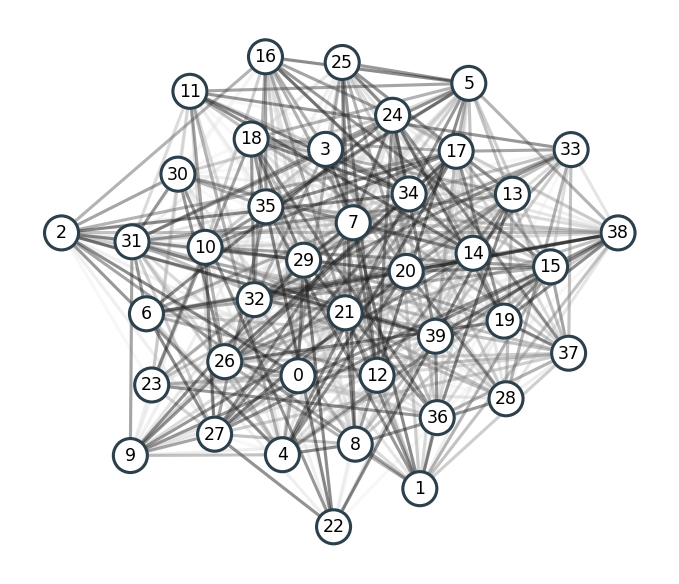

In [4]:
random.seed(42)
g1_pos = {node: (random.randint(0,100)/100,random.randint(0,100)/100) for node in g1.nodes()}
Graph(g1, node_layout='spring',
node_layout_kwargs={"node_positions": g1_pos},
node_labels=True,
edge_width=0.5,
seed=42)
plt.show()

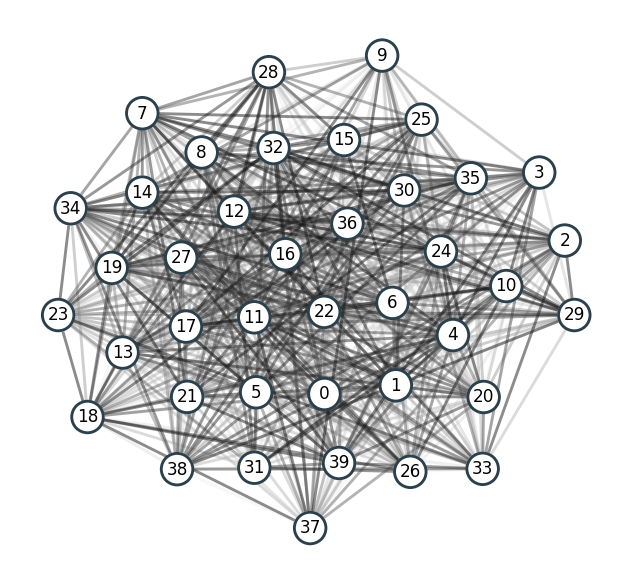

In [7]:
random.seed(42)
g2_pos = {node: (random.randint(0,100)/100,random.randint(0,100)/100) for node in g2.nodes()}
Graph(g2, node_layout='spring',
node_layout_kwargs={"node_positions": g2_pos},
node_labels=True,
edge_width=0.5,
seed=42)
plt.show()

In [8]:
def clustering(graph, n_clusters, chosen_alg):
    if chosen_alg == 'paris':
        alg = Paris()
    elif chosen_alg == 'louvain':
        alg = LouvainHierarchy()
    dendrogram = alg.fit_predict(nx.adjacency_matrix(graph).toarray())
    if chosen_alg == 'louvain':
        image = svg_dendrogram(dendrogram, names=list(graph.nodes), width=600)
    elif chosen_alg == 'paris':
        image = svg_dendrogram(dendrogram, names=list(graph.nodes), width=600, n_clusters=n_clusters)
    display(SVG(image))
    return cut_straight(dendrogram, n_clusters=n_clusters)

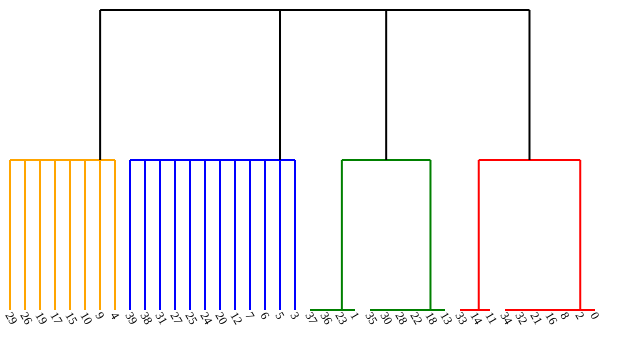

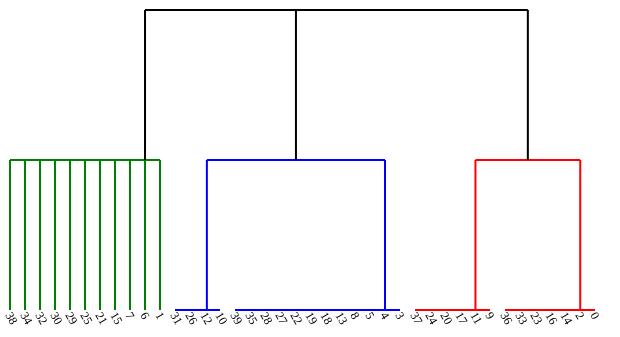

In [9]:
n_clusters_g1 = 3
n_clusters_g2 = 3
labels1 = clustering(g1, n_clusters_g1, 'louvain')
labels2 = clustering(g2, n_clusters_g2, 'louvain')
n_clusters_g1 = len(np.unique(labels1))
n_clusters_g2 = len(np.unique(labels1))

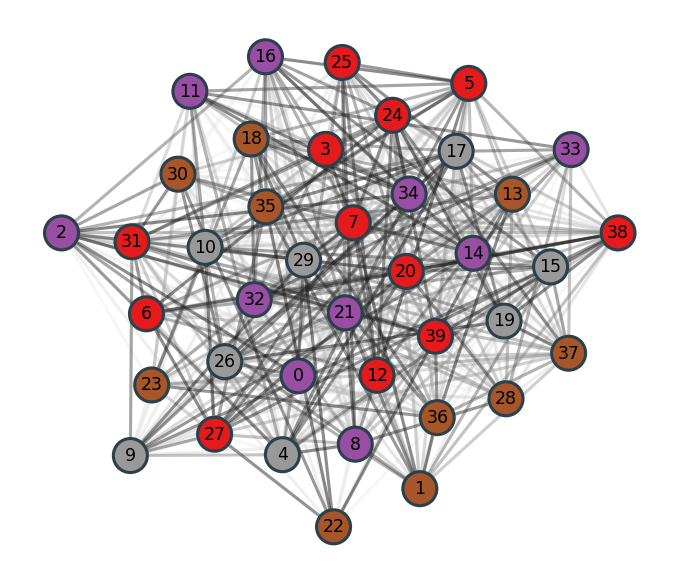

In [10]:
cmap1 = mcp.gen_color(cmap="Set1",n=n_clusters_g1)
Graph(g1, node_layout='spring',
node_labels=True,
edge_width=0.5,
node_layout_kwargs={'node_positions': g1_pos},
node_color={node: cmap1[clas] for node, clas in zip(g1.nodes(), labels1)})
plt.show()

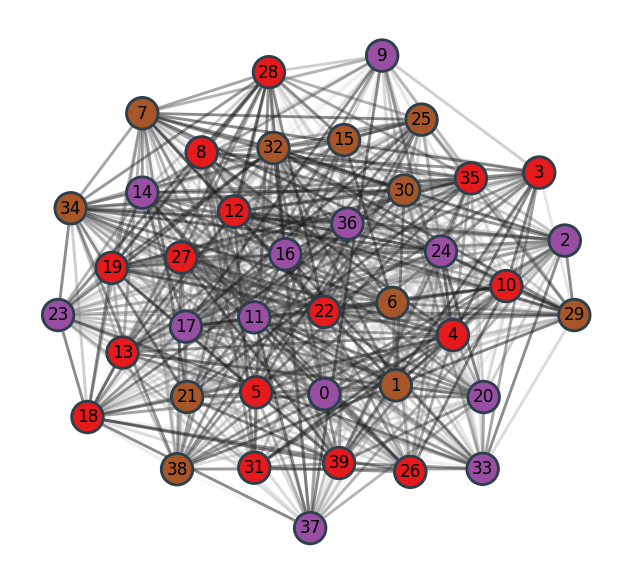

In [11]:
cmap2 = mcp.gen_color(cmap="Set1",n=n_clusters_g2)
Graph(g2, node_layout='spring',
node_labels=True,
edge_width=0.5,
node_layout_kwargs={'node_positions': g2_pos},
node_color={node: cmap2[clas] for node, clas in zip(g2.nodes(), labels2)})
plt.show()

c:\Users\Wojtek\.conda\envs\tass\lib\site-packages\netgraph\_edge_layout.py:978: RuntimeWarning: invalid value encountered in divide
  displacement = compatibility * delta / distance_squared[..., None]


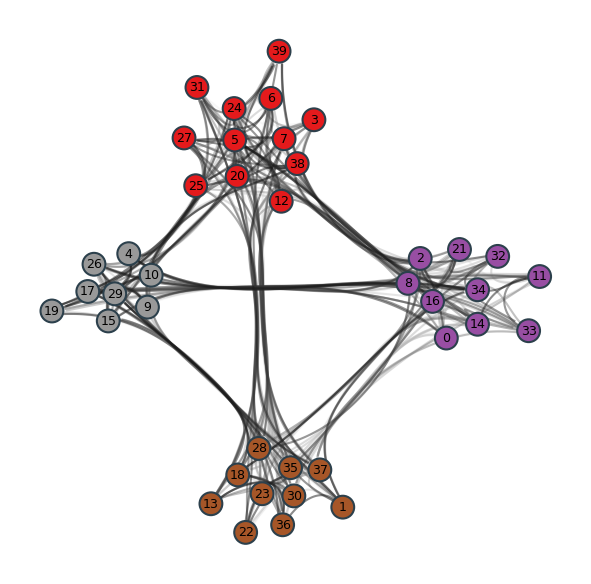

In [12]:
Graph(g1,
      node_labels=True,
      edge_width=0.5,
      node_color={node: cmap1[clas] for node, clas in zip(g1.nodes(), labels1)},
      node_layout='community', node_layout_kwargs={'node_to_community': {node: label for node, label in zip(g1.nodes(), labels1)}},
      edge_layout='bundled', edge_layout_kwargs=dict(k=2000),
)

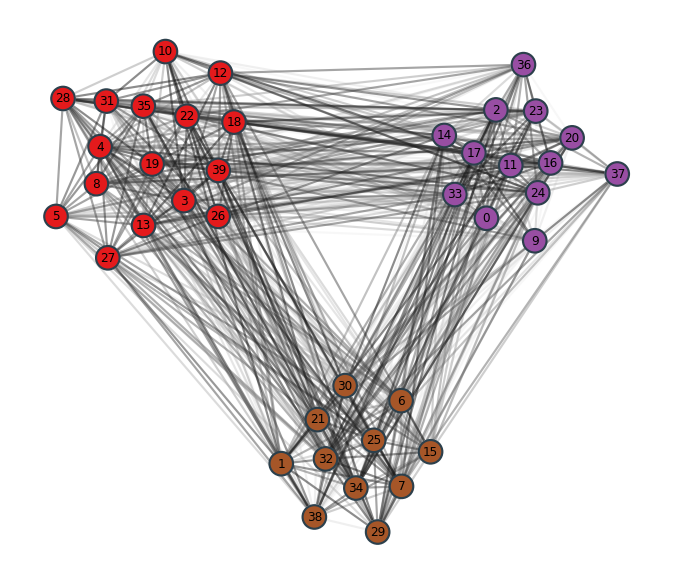

In [13]:
Graph(g2,
      node_labels=True,
      edge_width=0.5,
      node_color={node: cmap1[clas] for node, clas in zip(g2.nodes(), labels2)},
      node_layout='community', node_layout_kwargs={'node_to_community': {node: label for node, label in zip(g2.nodes(), labels2)}},
      #edge_layout='bundled', edge_layout_kwargs=dict(k=2000),
)

In [14]:
def jaccard_similarity(set1, set2):
    c = set1.intersection(set2)
    d = set1.union(set2)
    return len(c) / len(d)

In [15]:
def cluster_similarity_report(g1, g2, g1_n_clusters, g2_n_clusters, g1_labels, g2_labels):
    g1_clusters = [set() for _ in range(g1_n_clusters)]
    g2_clusters = [set() for _ in range(g2_n_clusters)]
    for node, clas in zip(g1.nodes, g1_labels):
        g1_clusters[clas].add(node)
    for node, clas in zip(g2.nodes, g2_labels):
        g2_clusters[clas].add(node)
    similarities = np.zeros((g1_n_clusters, g2_n_clusters))
    for i, g1_cluster in enumerate(g1_clusters):
        for j, g2_cluster in enumerate(g2_clusters):
            sim = jaccard_similarity(g1_cluster, g2_cluster)
            similarities[i, j] = sim
    return similarities, g1_clusters, g2_clusters


In [16]:
report, g1_clusters, g2_clusters = cluster_similarity_report(g1, g2, n_clusters_g1, n_clusters_g2, labels1, labels2)

Text(77.08333333333334, 0.5, 'g1')

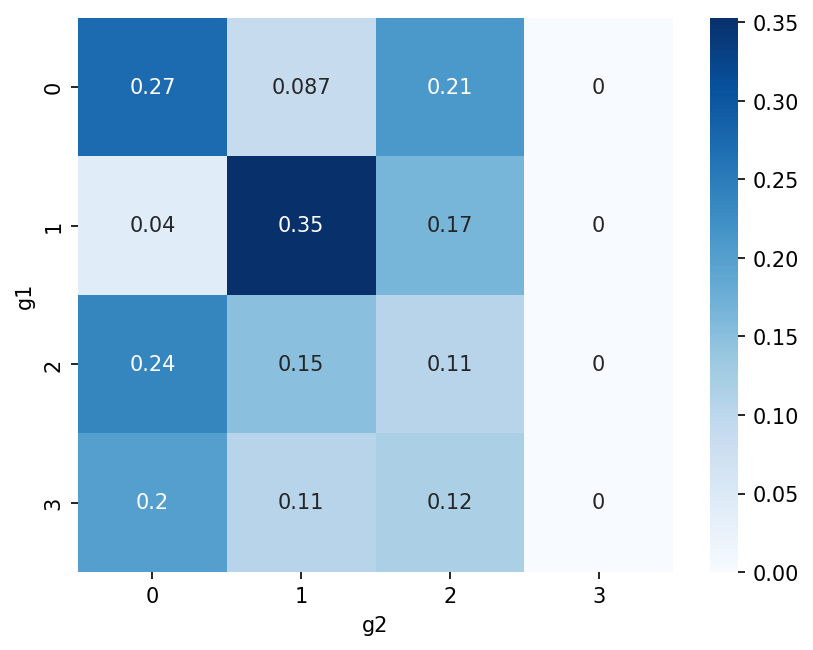

In [17]:
ax = sns.heatmap(report, annot=True, cmap='Blues')
ax.set_xlabel('g2')
ax.set_ylabel('g1')

In [18]:
g1_n = 1
g2_n = 1
g1_members = sorted(g1_clusters[g1_n])
g2_members = sorted(g2_clusters[g2_n])
all_unique_members = set(g1_members+g2_members)
df = pd.DataFrame(columns=['g1', 'g2'], index=list(all_unique_members))
for member in all_unique_members:
    df.loc[member, 'g1'] = 'x' if member in g1_members else ''
    df.loc[member, 'g2'] = 'x' if member in g2_members else ''

In [19]:
df

,g1,g2
0,x,x
32,x,
2,x,x
33,x,x
34,x,
36,,x
37,,x
8,x,
9,,x
11,x,x
